In [1]:
# CPU/GPU selection: run this cell before importing jax or mgp elsewhere.
# After changing MODE, restart the kernel and run all cells from the top.
# GPU mode requires CUDA-enabled JAX in a Linux/WSL2 kernel.
import os

MODE = "cpu"  # "cpu" or "gpu"
if MODE not in {"cpu", "gpu"}:
    raise ValueError('MODE must be "cpu" or "gpu".')

# Keep CPU available in GPU mode for operations explicitly placed on CPU.
os.environ["JAX_PLATFORMS"] = "cpu" if MODE == "cpu" else "cuda,cpu"

import jax
backend = jax.default_backend()
if backend != MODE:
    raise RuntimeError("Device mode has changed: restart the kernel and run all cells.")
print("Backend:", backend)
print("Devices:", jax.devices())

Backend: cpu
Devices: [CpuDevice(id=0)]


# Demo 2: `mgp` unified interface — sparse random loadings, heteroscedastic noise

**Model** (Bhattacharya & Dunson 2011): $x_i = B\eta_i + \varepsilon_i$,
$\eta_i \sim \mathcal N_K(0, I)$, $\varepsilon_i \sim \mathcal N_p(0, \Omega)$,
$\Omega$ diagonal, with the multiplicative gamma process prior
$B_{jk} \mid \omega_{jk}, T_k \sim \mathcal N(0, (\omega_{jk} T_k)^{-1})$,
$T_k = \prod_{\ell \le k} \delta_\ell$. Increasing shrinkage with the column index suppresses redundant factors.

**Data design** ($n = 100 \ll p = 1000$, $r = 5$ true factors):

- entries of $B_0$ are $\mathrm{Bernoulli}(1/3) \times U(0,1)$ — sparse random loadings with about two thirds exact zeros;
- $\Omega_0 = \mathrm{diag}(\sigma_j^2)$ with $\sigma_j^2 \sim U(0.1, 1.0)$ — **heteroscedastic** noise;
- $\Sigma_0 = B_0 B_0^\top + \Omega_0$.

**Inference** through the unified `mgp` interface on the same data: `GibbsMGP` (exact MCMC) and `CaviMGP` (fast deterministic approximation). Diagnostics cover heteroscedastic noise recovery, loading structure, covariance and subspace recovery, posterior covariance uncertainty, MCMC mixing, and factor switching through independent RSP alignment and paired factor scores.

In [2]:
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# Locate the repository root both in notebooks and when run as a script.
try:
    root = Path(__file__).resolve().parents[1]
except NameError:
    root = None
if root is None or not (root / "mgp" / "__init__.py").is_file():
    root = next((d for d in (Path.cwd(), *Path.cwd().parents)
                 if (d / "mgp" / "__init__.py").is_file()), None)
if root is None:
    raise RuntimeError(
        "cannot locate the mgp package; open the repository or one of its "
        "subdirectories as the working directory")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import jax
from mgp import CaviMGP, GibbsMGP

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#5b6472",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6eaf0",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlepad": 8,
    "axes.labelsize": 10,
    "axes.labelcolor": "#30363f",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.color": "#30363f",
    "ytick.color": "#30363f",
    "legend.fontsize": 9,
    "legend.frameon": False,
    "font.family": "DejaVu Sans",
})
C_GIBBS, C_CAVI, C_TRUE, C_SHRUNK = "#2f6fd0", "#e07b39", "#b03a2e", "#c9d3df"

print("package root:", root, "| jax backend:", jax.default_backend())

package root: C:\Users\kexio\Documents\GitHub\MGP_BFM | jax backend: cpu


## 1. Simulate the data (sparse loadings and heteroscedastic noise)

In [3]:
from scipy.stats import uniform

DATA_SEED = 12
SAMPLER_SEED = 2026
np.random.seed(DATA_SEED)
print(f"Seeds: data={DATA_SEED}, Gibbs/scores={SAMPLER_SEED}")

P, K0, N = 1000, 5, 100
B_0 = np.random.binomial(1, 1 / 3, (P, K0)) * np.random.rand(P, K0)
s2_true = uniform.rvs(loc=0.1, scale=0.9, size=P)
cov_0 = B_0 @ B_0.T + np.diag(s2_true)
X = np.random.multivariate_normal(np.zeros(P), cov_0, N)

Sig_true = cov_0
print(f"X: {X.shape}  (n = {N}, p = {P}, true factors r = {K0})")
print(f"loading sparsity (exact zeros): {(B_0 == 0).mean():.2%}")

Seeds: data=12, Gibbs/scores=2026


X: (100, 1000)  (n = 100, p = 1000, true factors r = 5)
loading sparsity (exact zeros): 67.50%


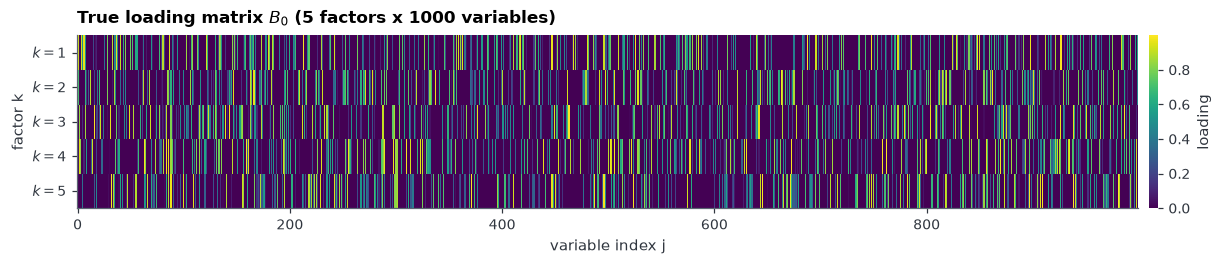

In [4]:
fig, ax = plt.subplots(figsize=(11, 2.3), constrained_layout=True)
im = ax.imshow(B_0.T, aspect="auto", interpolation="nearest", cmap="viridis")
ax.set_title(f"True loading matrix $B_0$ ({K0} factors x {P} variables)", loc="left")
ax.set_xlabel("variable index j")
ax.set_ylabel("factor k")
ax.set_yticks(np.arange(K0))
ax.set_yticklabels([f"$k={k + 1}$" for k in range(K0)])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("loading")
cb.outline.set_visible(False)
plt.show()

## 2. Fit both estimators on the same data

Both estimators use the explicit MGP prior `nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1`, truncation `K=50`, `center=True`, and `standardize=False`. Gibbs uses `n_iter=20000`, `burn_in=10000`, `thin=10` (1000 retained draws), `SAMPLER_SEED=2026`, and `precision="float32"`. CAVI uses `max_iter=1000`, `tol=1e-1`, and `precision="float64"`; neither fit relies on a process-wide precision default.

CAVI checks `abs(Lvar_t - Lvar_prev) < tol` after each complete sweep. Its independent `drop_budget`, whose MGP default is `0.5`, rejects larger ELBO decreases with `FloatingPointError` instead of reporting convergence.

The CAVI loading-mean count uses `LINF_THRESHOLD = 0.1` throughout, including the aligned summaries. Gibbs retains its credible-interval selection rule.

In [5]:
K = 50
LINF_THRESHOLD = 0.1

t0 = time.perf_counter()
gs = GibbsMGP(
    K=K, nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1,
    n_iter=20000, burn_in=10000, thin=10, seed=SAMPLER_SEED,
    precision="float32", center=True, standardize=False, verbose=False,
).fit(X)
wall_gs = time.perf_counter() - t0
S = gs.B_samples_.shape[0]
assert S == 1000

t0 = time.perf_counter()
vi = CaviMGP(
    K=K, nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1,
    max_iter=1000, tol=1e-1, precision="float64",
    center=True, standardize=False,
).fit(X)
wall_vi = time.perf_counter() - t0

print("-" * 86)
print(f"GibbsMGP | {S} kept draws | scan {gs.runtime_sec_:.1f}s "
      f"({1e3 * gs.runtime_sec_ / gs.n_iter:.1f} ms/sweep) | wall {wall_gs:.1f}s | "
      f"seed={gs.seed_} | precision={gs.precision_used_}")
print(f"CaviMGP  | converged={vi.converged_} ({vi.stop_reason_}) in "
      f"{vi.n_iter_} sweeps | ELBO={vi.elbo_[-1]:.1f} | loop {vi.runtime_sec_:.1f}s | "
      f"wall {wall_vi:.1f}s | precision={vi.precision_used_}")
print("-" * 86)

--------------------------------------------------------------------------------------
GibbsMGP | 1000 kept draws | scan 647.5s (32.4 ms/sweep) | wall 652.7s | seed=2026 | precision=float32
CaviMGP  | converged=False (max_iter) in 1000 sweeps | ELBO=-123661.5 | loop 59.4s | wall 62.3s | precision=float64
--------------------------------------------------------------------------------------


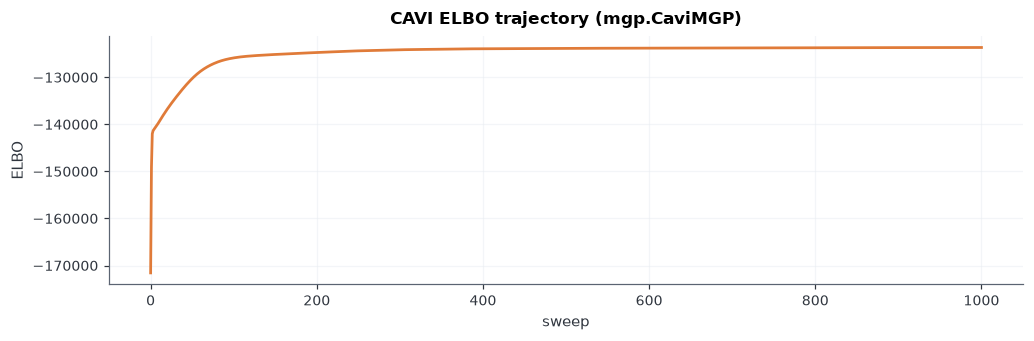

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.2))
vi.plot_elbo(ax=ax, show=False, title="CAVI ELBO trajectory (mgp.CaviMGP)")
ax.lines[0].set_color(C_CAVI)
ax.lines[0].set_linewidth(1.8)
ax.grid(True, alpha=0.45)
plt.show()

## 3. Automatic selection of the factor dimension

Compare Gibbs' empirical marginal credible-interval count with two CAVI summaries: `method="credible"` uses the Gaussian interval $|\mu_{jk}| > z\sqrt{V_{jkk}}$, while `method="linf"` counts columns satisfying $\max_j |\mu_{jk}| > 0.1$ (`threshold=0.1`). Equality at the threshold is inactive. The credible-interval rule accounts for marginal posterior uncertainty; the threshold rule uses loading means only, so their counts can differ. Compare the computed counts with the true factor dimension $r=5$.

The bars below show column $L_2$ norms for scale and shrinkage visualization. These plotted norms are distinct from both the credible-interval criterion and the CAVI $L_\infty$ threshold criterion.

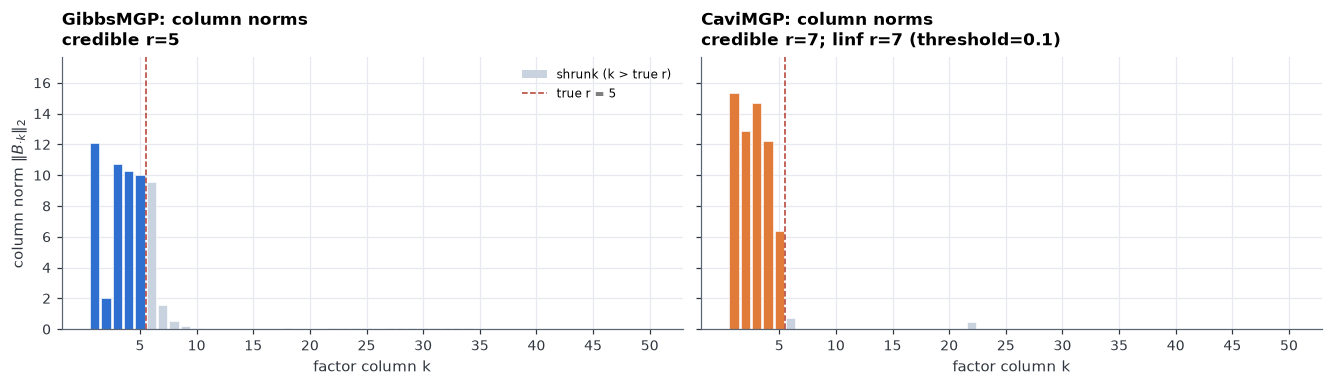

column norms (Gibbs): [1.2112e+01 2.0460e+00 1.0701e+01 1.0291e+01 1.0020e+01 9.5910e+00
 1.6000e+00 5.5600e-01 2.1600e-01 7.5000e-02 3.8000e-02 3.3000e-02
 2.6000e-02 3.4000e-02 3.6000e-02 3.0000e-02 3.6000e-02 4.4000e-02
 3.0000e-02 3.4000e-02 3.4000e-02 4.5000e-02 5.4000e-02 5.0000e-02
 5.5000e-02 4.2000e-02 4.8000e-02 7.8000e-02 9.0000e-02 6.3000e-02
 7.6000e-02 7.4000e-02 7.0000e-02 5.3000e-02 4.3000e-02 3.3000e-02
 2.0000e-02 1.3000e-02 7.0000e-03 5.0000e-03 4.0000e-03 2.0000e-03
 1.0000e-03 1.0000e-03 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00]
column norms (CAVI):  [15.347 12.902 14.721 12.221  6.4    0.745  0.     0.     0.     0.
  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
  0.     0.476  0.     0.     0.     0.     0.     0.     0.     0.
  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
true factor count: 5
Gibbs n_factors (credible): 5
C

In [7]:
r_gs_credible = gs.n_factors()
r_vi_credible = vi.n_factors(method="credible")
r_vi_linf = vi.n_factors(method="linf", threshold=LINF_THRESHOLD)

colnorm_gs = np.linalg.norm(gs.B_samples_, axis=1).mean(0)
colnorm_vi = np.linalg.norm(vi.mu_, axis=0)

all_norms = (colnorm_gs, colnorm_vi)
ymax = max(float(n.max()) for n in all_norms) * 1.15


def _draw_colnorms(ax, norms, count_label, color, title):
    xs = np.arange(1, len(norms) + 1)
    ax.bar(xs, norms, width=0.82,
           color=np.where(xs <= K0, color, C_SHRUNK),
           edgecolor="white", linewidth=0.4)
    ax.axvline(K0 + 0.5, color=C_TRUE, ls="--", lw=1.0)
    ax.set_title(f"{title}: column norms\n{count_label}", loc="left")
    ax.set_xlabel("factor column k")
    ax.set_ylim(0, ymax)
    ax.set_xticks(np.arange(5, len(norms) + 1, 5))


fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True,
                         sharey=True)
_draw_colnorms(axes[0], colnorm_gs, f"credible r={r_gs_credible}",
               C_GIBBS, "GibbsMGP")
_draw_colnorms(axes[1], colnorm_vi,
               f"credible r={r_vi_credible}; linf r={r_vi_linf} "
               f"(threshold={LINF_THRESHOLD:g})",
               C_CAVI, "CaviMGP")
axes[0].set_ylabel(r"column norm $\|B_{\cdot k}\|_2$")

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

handles = [
    Patch(facecolor=C_SHRUNK, label="shrunk (k > true r)"),
    Line2D([0], [0], color=C_TRUE, ls="--", lw=1.0,
           label=f"true r = {K0}"),
]
axes[0].legend(handles=handles, loc="upper right", fontsize=8)
plt.show()

print("column norms (Gibbs):", np.round(colnorm_gs, 3))
print("column norms (CAVI): ", np.round(colnorm_vi, 3))
print(f"true factor count: {K0}")
print(f"Gibbs n_factors (credible): {r_gs_credible}")
print(f"CAVI n_factors (credible): {r_vi_credible}")
print(f"CAVI n_factors (linf, threshold={LINF_THRESHOLD:g}): {r_vi_linf}")

## 4. Recovery of the heteroscedastic noise variances

$\sigma^2$ estimates vs the truth: the Gibbs posterior mean and the variational posterior mean $E_q[\sigma_j^2] = \beta_j/(\alpha_n - 1)$. The scatter plot, correlations, and mean absolute errors are all computed from the current run.

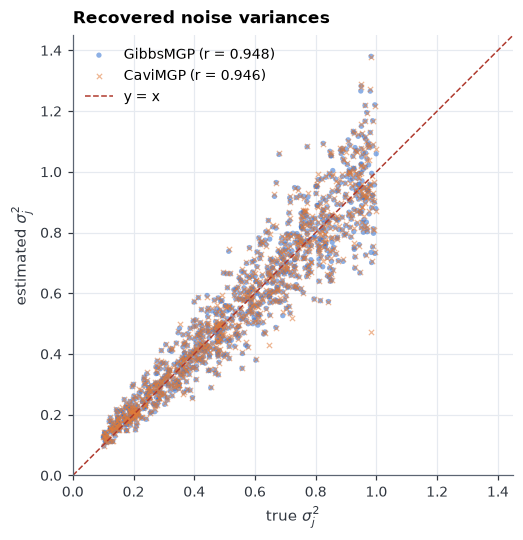

corr with truth: Gibbs = 0.9477, CAVI = 0.9458
mean |err|:      Gibbs = 0.0629, CAVI = 0.0636


In [8]:
corr_gs = np.corrcoef(s2_true, gs.sigma2_hat_)[0, 1]
corr_vi = np.corrcoef(s2_true, vi.sigma2_hat_)[0, 1]
err_gs = np.abs(gs.sigma2_hat_ - s2_true).mean()
err_vi = np.abs(vi.sigma2_hat_ - s2_true).mean()

fig, ax = plt.subplots(figsize=(5.6, 4.8), constrained_layout=True)
ax.scatter(s2_true, gs.sigma2_hat_, s=12, alpha=0.55, color=C_GIBBS,
           edgecolors="none", label=f"GibbsMGP (r = {corr_gs:.3f})")
ax.scatter(s2_true, vi.sigma2_hat_, s=12, alpha=0.55, color=C_CAVI,
           marker="x", linewidths=0.8, label=f"CaviMGP (r = {corr_vi:.3f})")
lim = [0, 1.05 * max(float(s2_true.max()), float(gs.sigma2_hat_.max()),
                     float(vi.sigma2_hat_.max()))]
ax.plot(lim, lim, color=C_TRUE, ls="--", lw=1.0, label="y = x")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_aspect("equal")
ax.set_xlabel(r"true $\sigma_j^2$")
ax.set_ylabel(r"estimated $\sigma_j^2$")
ax.set_title("Recovered noise variances", loc="left")
ax.legend(loc="upper left")
plt.show()

print(f"corr with truth: Gibbs = {corr_gs:.4f}, CAVI = {corr_vi:.4f}")
print(f"mean |err|:      Gibbs = {err_gs:.4f}, CAVI = {err_vi:.4f}")

## 5. Recovered loading structure

$|B_0|$ (truth, 5 columns) vs the posterior-mean loadings $|\hat B|$ of `GibbsMGP` and the variational means $|\mu|$ of `CaviMGP` (`K=50` columns). All three panels share one color scale.

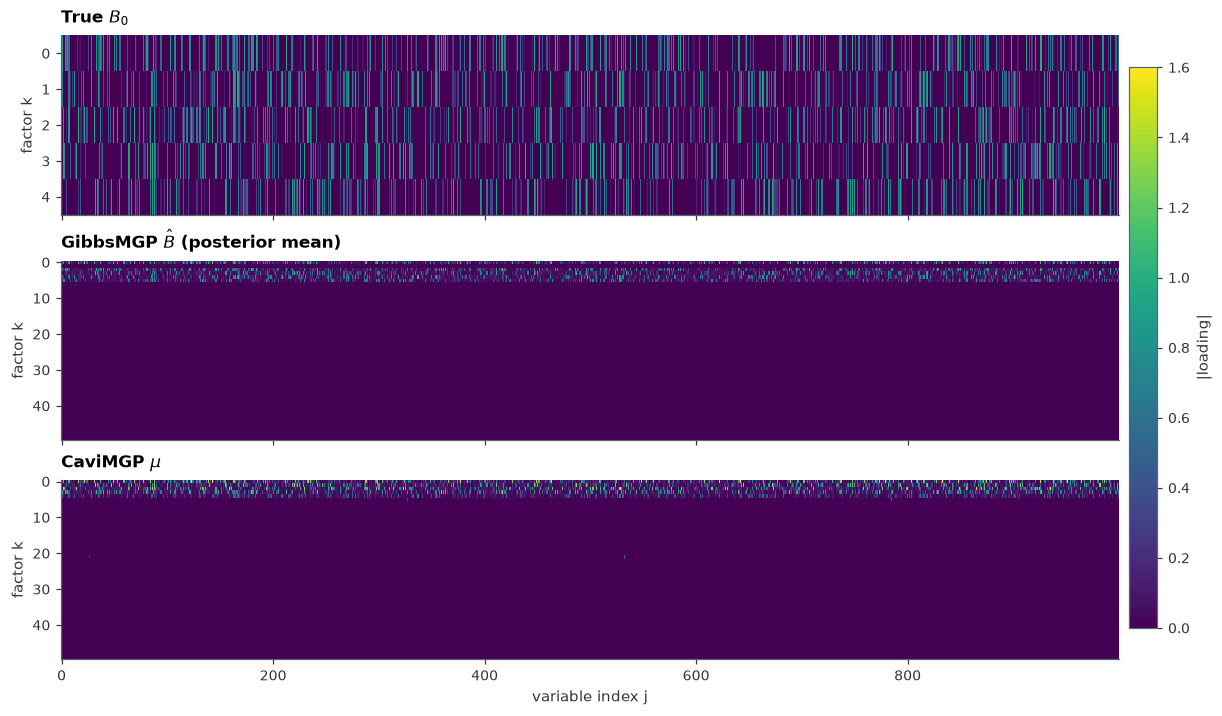

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6.4), constrained_layout=True,
                         sharex=True)
matrices = (np.abs(B_0), np.abs(gs.B_hat_), np.abs(vi.mu_))
names = ("True $B_0$", "GibbsMGP $\\hat B$ (posterior mean)", "CaviMGP $\\mu$")
vmax = max(float(M.max()) for M in matrices)
for ax, M, name in zip(axes, matrices, names):
    im = ax.imshow(M.T, aspect="auto", interpolation="nearest", cmap="viridis",
                   vmin=0, vmax=vmax)
    ax.set_title(name, loc="left")
    ax.set_ylabel("factor k")
    ax.grid(False)
axes[-1].set_xlabel("variable index j")
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.9)
cb.set_label("|loading|")
plt.show()

## 6. Covariance and factor-subspace recovery

For each estimator, report both the plug-in covariance and the posterior-mean covariance using
\[
\text{Frobenius error}=\|\widehat\Sigma-\Sigma_0\|_F,
\qquad
\text{relative Frobenius error}
=\frac{\|\widehat\Sigma-\Sigma_0\|_F}{\|\Sigma_0\|_F}.
\]
The table and plots report both errors **before RSP alignment**. The absolute error retains the covariance scale; the relative error uses the same true-covariance norm for all four estimates. Subspace checks select the $r$ estimated loading columns with the largest $L_2$ norms rather than assuming that the first $r$ columns are the active ones.

Covariance estimation errors before RSP alignment
||Sigma_true||_F = 271.420766
Estimator / summary             Frobenius error   Relative Frobenius error
GibbsMGP plug-in                     102.696922                   0.378368
GibbsMGP Sigma_mean_                 102.763202                   0.378612
CaviMGP plug-in                      207.627040                   0.764964
CaviMGP Sigma_mean_                  207.680268                   0.765160
principal-angle cosines (GibbsMGP, top 5 columns by norm): [0.9897 0.9774 0.9757 0.9726 0.9681]
  selected columns (1-based): [1, 3, 4, 5, 6]
principal-angle cosines (CaviMGP, top 5 columns by norm): [0.9897 0.9772 0.9753 0.9724 0.969 ]
  selected columns (1-based): [1, 3, 2, 4, 5]


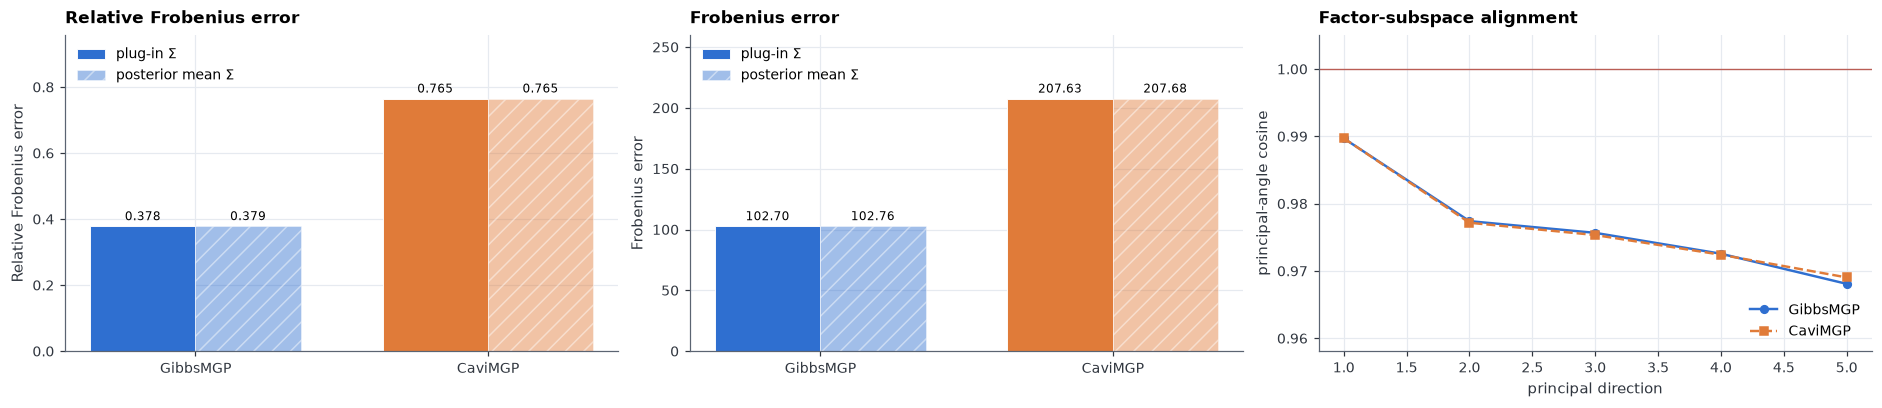

In [10]:
Sig_gs_mean = gs.Sigma_mean_
Sig_vi_mean = vi.Sigma_mean_
norm_Sig_true = float(np.linalg.norm(Sig_true, ord="fro"))


def froerr(Sig):
    return float(np.linalg.norm(Sig - Sig_true, ord="fro"))


def relerr(Sig):
    return froerr(Sig) / norm_Sig_true


fro_gs_plug, fro_gs_mean = froerr(gs.Sigma_), froerr(Sig_gs_mean)
fro_vi_plug, fro_vi_mean = froerr(vi.Sigma_), froerr(Sig_vi_mean)
rel_gs_plug, rel_gs_mean = fro_gs_plug / norm_Sig_true, fro_gs_mean / norm_Sig_true
rel_vi_plug, rel_vi_mean = fro_vi_plug / norm_Sig_true, fro_vi_mean / norm_Sig_true
covariance_errors = {
    "GibbsMGP plug-in": (fro_gs_plug, rel_gs_plug),
    "GibbsMGP Sigma_mean_": (fro_gs_mean, rel_gs_mean),
    "CaviMGP plug-in": (fro_vi_plug, rel_vi_plug),
    "CaviMGP Sigma_mean_": (fro_vi_mean, rel_vi_mean),
}
print("Covariance estimation errors before RSP alignment")
print(f"||Sigma_true||_F = {norm_Sig_true:.6f}")
print(f"{'Estimator / summary':<26} {'Frobenius error':>20} {'Relative Frobenius error':>26}")
for label, (absolute, relative) in covariance_errors.items():
    print(f"{label:<26} {absolute:20.6f} {relative:26.6f}")

U_true = np.linalg.qr(B_0)[0][:, :K0]
cos_gs, cos_vi = [], []
for name, Bh, store in (("GibbsMGP", gs.B_hat_, cos_gs),
                        ("CaviMGP", vi.B_hat_, cos_vi)):
    top = np.argsort(np.linalg.norm(Bh, axis=0))[::-1][:K0]
    U_post = np.linalg.qr(Bh[:, top])[0]
    cosines = np.linalg.svd(U_post.T @ U_true, compute_uv=False)
    store.extend(cosines.tolist())
    print(f"principal-angle cosines ({name}, top {K0} columns by norm):",
          np.round(cosines, 4))
    print("  selected columns (1-based):", (top + 1).tolist())

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), constrained_layout=True)
x = np.arange(2)
width = 0.36
panels = (
    (axes[0], [rel_gs_plug, rel_vi_plug], [rel_gs_mean, rel_vi_mean],
     "Relative Frobenius error", "%.3f"),
    (axes[1], [fro_gs_plug, fro_vi_plug], [fro_gs_mean, fro_vi_mean],
     "Frobenius error", "%.2f"),
)
for ax, plug_in, posterior_mean, label, number_format in panels:
    b1 = ax.bar(x - width / 2, plug_in, width,
                color=[C_GIBBS, C_CAVI], edgecolor="white", linewidth=0.6,
                label=r"plug-in $\Sigma$")
    b2 = ax.bar(x + width / 2, posterior_mean, width,
                color=[C_GIBBS, C_CAVI], alpha=0.45, hatch="//",
                edgecolor="white", linewidth=0.6,
                label=r"posterior mean $\Sigma$")
    ax.set_xticks(x)
    ax.set_xticklabels(["GibbsMGP", "CaviMGP"])
    ax.set_ylabel(label)
    ax.set_title(label, loc="left")
    ax.set_ylim(0, 1.25 * max(*plug_in, *posterior_mean))
    ax.legend(loc="upper left")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt=number_format, padding=2, fontsize=8)

axes[2].plot(np.arange(1, K0 + 1), cos_gs, "o-", ms=5, lw=1.6,
             color=C_GIBBS, label="GibbsMGP")
axes[2].plot(np.arange(1, K0 + 1), cos_vi, "s--", ms=5, lw=1.6,
             color=C_CAVI, label="CaviMGP")
axes[2].axhline(1.0, color=C_TRUE, lw=0.9, alpha=0.8)
axes[2].set_ylim(min(min(cos_gs), min(cos_vi)) - 0.01, 1.005)
axes[2].set_xlabel("principal direction")
axes[2].set_ylabel("principal-angle cosine")
axes[2].set_title("Factor-subspace alignment", loc="left")
axes[2].legend(loc="lower right")
plt.show()

## 6b. Covariance heatmaps: truth vs posterior means

Heatmaps of (a) the true covariance $\Sigma_0$, (b) the Gibbs posterior-mean covariance $E[\Sigma\mid X]$ (`gs.Sigma_mean_`) and (c) the CAVI posterior-mean covariance $E_q[\Sigma]$ (`vi.Sigma_mean_`). All panels share one color scale.

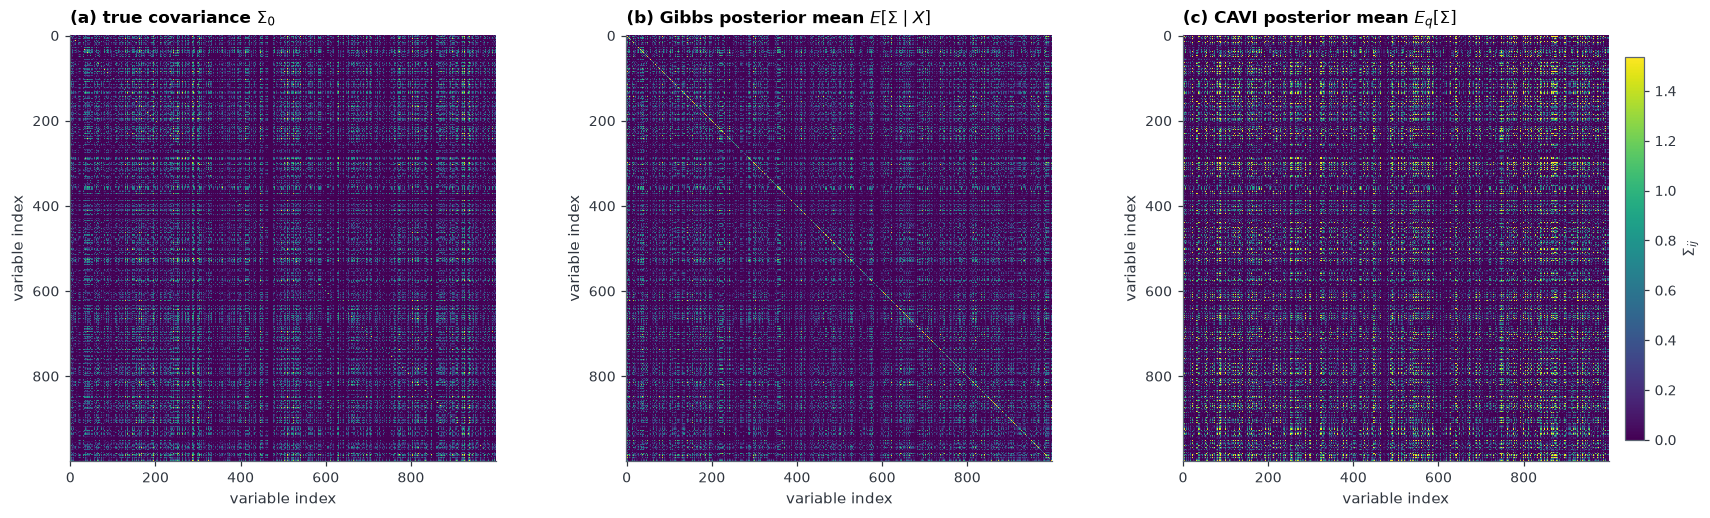

In [11]:
panels = (
    (r"(a) true covariance $\Sigma_0$", Sig_true),
    (r"(b) Gibbs posterior mean $E[\Sigma\mid X]$", Sig_gs_mean),
    (r"(c) CAVI posterior mean $E_q[\Sigma]$", Sig_vi_mean),
)
vmax = float(np.percentile(
    np.concatenate([np.asarray(M, dtype=float).ravel() for _, M in panels]),
    99.5,
))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for ax, (title, M) in zip(axes, panels):
    im = ax.imshow(M, cmap="viridis", vmin=0.0, vmax=vmax,
                   interpolation="nearest")
    ax.set_title(title, loc="left")
    ax.set_xlabel("variable index")
    ax.set_ylabel("variable index")
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.9)
cb.set_label(r"$\Sigma_{ij}$")
plt.show()

## 6c. Posterior uncertainty of $\Sigma$

Both estimators expose posterior moments of $\Sigma = BB^\top + \Omega$: `Sigma_mean_`, `Sigma_var_`/`Sigma_sd_`, and `cov_Sigma(pairs)`. For `GibbsMGP` these are Monte Carlo estimates from the retained draws; for `CaviMGP` they are closed-form moments of the mean-field variational posterior. Diagonal variances (`Sigma_diag_var_`) and selected pair covariances use all Gibbs draws and avoid the full $p \times p$ variance scan. The full variance matrix is additionally guarded by a compute budget for large $p$.

posterior SD of Sigma_jj: Gibbs mean = 0.146, CAVI mean = 0.170
Gibbs: Var(Sigma_01) = 1.454e-02, Cov(Sigma_01, Sigma_23) = -2.277e-05 (all 1000 draws)


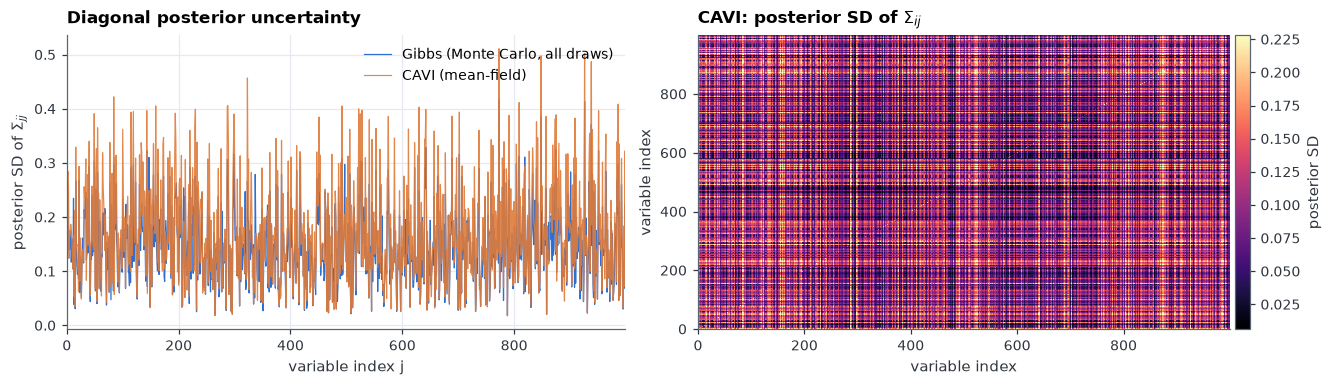

In [12]:
gs_sd_diag = np.sqrt(gs.Sigma_diag_var_)
vi_sd_diag = np.sqrt(np.diag(vi.Sigma_var_))
pair_var = float(gs.cov_Sigma([((0, 1), (0, 1))])[0])
pair_cov = float(gs.cov_Sigma([((0, 1), (2, 3))])[0])
print(f"posterior SD of Sigma_jj: Gibbs mean = {gs_sd_diag.mean():.3f}, "
      f"CAVI mean = {vi_sd_diag.mean():.3f}")
print(f"Gibbs: Var(Sigma_01) = {pair_var:.3e}, "
      f"Cov(Sigma_01, Sigma_23) = {pair_cov:.3e} "
      f"(all {gs.B_samples_.shape[0]} draws)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.05, 1.0]})
axes[0].plot(gs_sd_diag, color=C_GIBBS, lw=0.8,
             label="Gibbs (Monte Carlo, all draws)")
axes[0].plot(vi_sd_diag, color=C_CAVI, lw=0.8, alpha=0.9,
             label="CAVI (mean-field)")
axes[0].set_xlabel("variable index j")
axes[0].set_ylabel(r"posterior SD of $\Sigma_{jj}$")
axes[0].set_title("Diagonal posterior uncertainty", loc="left")
axes[0].set_xlim(0, P - 1)
axes[0].legend(loc="upper right")

im = axes[1].imshow(vi.Sigma_sd_, aspect="auto", origin="lower",
                    interpolation="nearest", cmap="magma",
                    vmax=float(np.percentile(vi.Sigma_sd_, 99)))
axes[1].set_xlabel("variable index")
axes[1].set_ylabel("variable index")
axes[1].set_title(r"CAVI: posterior SD of $\Sigma_{ij}$", loc="left")
axes[1].grid(False)
cb = fig.colorbar(im, ax=axes[1], pad=0.01)
cb.set_label("posterior SD")
plt.show()

## 7. MCMC mixing diagnostics (ESS, ArviZ)

This section requires the optional ArviZ dependency; from the repository root, install it with `python -m pip install -e ".[ess]"` if needed. The ESS table, heatmap, histogram, and rolling noise trace all use the retained Gibbs draws from this run.

B       min=     6.4  median=   957.5  mean=   916.0  max=  1334.5  (draws=1000)
sigma2  min=    46.2  median=   957.9  mean=   944.3  max=  1263.1  (draws=1000)


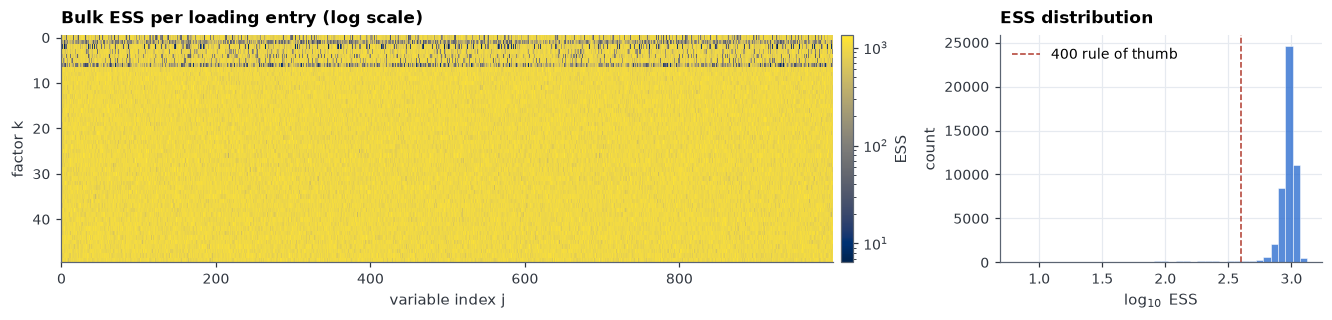

In [13]:
summary = gs.ess_summary()
for k, v in summary.items():
    print(f"{k:7s} min={v['min']:8.1f}  median={v['median']:8.1f}  "
          f"mean={v['mean']:8.1f}  max={v['max']:8.1f}  "
          f"(draws={v['n_draws']})")

from matplotlib.colors import LogNorm

ess_B = gs.ess()["B"]
vals = ess_B.ravel()
vals = vals[np.isfinite(vals) & (vals > 0)]
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2.4, 1.0]})
im = axes[0].imshow(ess_B.T, aspect="auto", interpolation="nearest",
                    norm=LogNorm(vmin=max(1.0, float(np.min(vals))),
                                 vmax=float(np.max(vals))), cmap="cividis")
axes[0].set_title("Bulk ESS per loading entry (log scale)", loc="left")
axes[0].set_xlabel("variable index j")
axes[0].set_ylabel("factor k")
axes[0].grid(False)
cb = fig.colorbar(im, ax=axes[0], pad=0.01)
cb.set_label("ESS")
axes[1].hist(np.log10(vals), bins=40, color=C_GIBBS, alpha=0.8,
             edgecolor="white", linewidth=0.4)
axes[1].axvline(np.log10(400.0), color=C_TRUE, ls="--", lw=1.0,
                label="400 rule of thumb")
axes[1].set_title("ESS distribution", loc="left")
axes[1].set_xlabel(r"$\log_{10}$ ESS")
axes[1].set_ylabel("count")
axes[1].legend(loc="upper left")
plt.show()

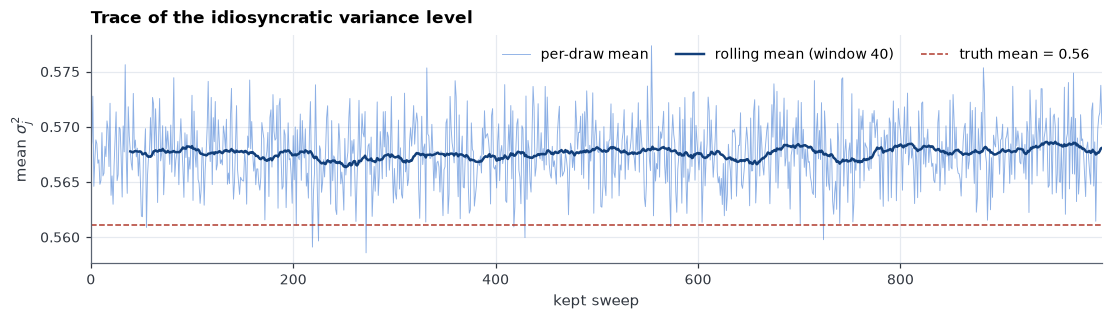

In [14]:
trace = gs.sigma2_samples_.mean(axis=1)
window = max(1, len(trace) // 25)
rolling = np.convolve(trace, np.ones(window) / window, mode="valid")

fig, ax = plt.subplots(figsize=(10, 2.8), constrained_layout=True)
ax.plot(trace, color=C_GIBBS, lw=0.6, alpha=0.55, label="per-draw mean")
ax.plot(np.arange(window - 1, len(trace)), rolling, color="#123f7a",
        lw=1.6, label=f"rolling mean (window {window})")
ax.axhline(float(s2_true.mean()), color=C_TRUE, ls="--", lw=1.0,
           label=f"truth mean = {float(s2_true.mean()):.2f}")
ax.set_xlabel("kept sweep")
ax.set_ylabel(r"mean $\sigma_j^2$")
ax.set_title("Trace of the idiosyncratic variance level", loc="left")
ax.set_xlim(0, len(trace) - 1)
ax.legend(loc="upper right", ncol=3)
plt.show()

## 8. Factor switching: RSP alignment and factor scores

Apply alignment explicitly after the original fitting, recovery, and ESS diagnostics above. For `K=50`, RSP's default assignment backend requires Optax; from the repository root, install `python -m pip install -e ".[rsp]"` if needed.

- **Gibbs:** `gs.align_factors()` aligns every retained draw and updates `gs.B_hat_` to their aligned mean. `B_samples_` and ESS remain based on the original draws. Each draw's covariance is unchanged, but the plug-in `gs.Sigma_` can change because it uses the outer product of the new mean. `gs.n_factors()` works after alignment; `use_aligned=True` builds intervals from the aligned draws.
- **CAVI:** `vi.align_factors()` independently orients `mu_[None, :, :]`, not an MCMC sample and not a matrix aligned to the Gibbs fit. It exposes `mu_aligned_`, score means `eta_aligned_ = W_aligned_.T`, and transformed covariances `V_aligned_` and `Phi_aligned_`. The original parameters, `B_hat_`, `Sigma_`, both original-coordinate factor counts, and ELBO are unchanged. Both `method="credible"` and `method="linf"` support `use_aligned=True`; general rotations can change either count.
- **Scores on demand:** `gs.sample_factors(X, ...)` draws scores conditional on each retained loading/noise pair. Pass the original uncentered `X`; the fitted centering offset is applied internally. These are fresh conditional draws, not historical intermediate scores from the Gibbs sweeps.

The signed heatmaps use one color scale for each estimator's before/after pair. Orientation alone does not establish better recovery: the column-dependent shrinkage prior is not invariant to general rotations or permutations. The CAVI outputs are transformed moments for interpretation, not a new CAVI optimum. Checks use one representative Gibbs draw and small covariance submatrices to keep memory and computation bounded.

In [15]:
gs_mean_raw = gs.B_samples_.mean(axis=0)
vi_mean_raw = vi.mu_.copy()
vi_elbo_before = tuple(vi.elbo_)
vi_count_before = vi.n_factors(method="credible")
vi_linf_count_before = vi.n_factors(method="linf", threshold=LINF_THRESHOLD)
check_features = np.unique(np.linspace(
    0, gs_mean_raw.shape[0] - 1, min(32, gs_mean_raw.shape[0]), dtype=int,
))
check_pairs = np.ix_(check_features, check_features)
noise_block = np.diag(gs.sigma2_hat_[check_features])
gs_plugin_raw_block = (gs_mean_raw[check_features]
                       @ gs_mean_raw[check_features].T + noise_block)
gs_sigma_mean_raw_block = Sig_gs_mean[check_pairs].copy()
vi_sigma_mean_raw_block = Sig_vi_mean[check_pairs].copy()

gs.align_factors()
vi.align_factors()

for name, model in (("Gibbs", gs), ("CAVI", vi)):
    result = model.rsp_result_
    print(f"{name} RSP: status={int(result.status_code)}, "
          f"stop={result.diagnostics['stop_reason']}, "
          f"iterations={int(result.n_iter)}, final loss={float(result.loss_final):.6g}")
    print("  diagnostics:", result.diagnostics)

np.testing.assert_allclose(gs.B_hat_, gs.B_aligned_.mean(axis=0),
                           rtol=2e-5, atol=2e-6)
np.testing.assert_array_equal(vi.B_hat_, vi_mean_raw)
assert tuple(vi.elbo_) == vi_elbo_before
assert vi.n_factors(method="credible") == vi_count_before
assert vi.n_factors(method="linf", threshold=LINF_THRESHOLD) == vi_linf_count_before
print("Gibbs aligned mean:", gs.B_hat_.shape,
      "| CAVI transformed mean:", vi.mu_aligned_.shape)
print("CAVI B_hat_, ELBO and both original-coordinate factor counts are unchanged.")

print(f"CAVI aligned n_factors (credible): "
      f"{vi.n_factors(method='credible', use_aligned=True)}")
print(f"CAVI aligned n_factors (linf, threshold={LINF_THRESHOLD:g}): "
      f"{vi.n_factors(method='linf', threshold=LINF_THRESHOLD, use_aligned=True)}")

Gibbs RSP: status=1, stop=converged_threshold, iterations=2, final loss=34910.1
  diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'optax', 'assignment_backend_requested': 'auto', 'polar': 'qdwh', 'varimax_svd_fallbacks': 1000, 'rotate_requested': True, 'varimax_applied': True, 'rotated': True, 'precision': 'float32', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}
CAVI RSP: status=1, stop=converged_threshold, iterations=2, final loss=0
  diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'optax', 'assignment_backend_requested': 'auto', 'polar': 'qdwh', 'varimax_svd_fallbacks': 1, 'rotate_requested': True, 'varimax_applied': True, 'rotated': True, 'precision': 'float64', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}
Gibbs aligned mean: (1000, 50) | CAVI transformed mean: (1000, 50)
CAVI B_hat_, ELBO and both original-coordinate factor counts are unchanged.
CAVI aligned n_

### 8a. Counts and all column-wise posterior-mean infinity norms

Both estimators use `nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1`. The table below compares Gibbs' credible-interval count and CAVI's credible-interval and loading-mean threshold counts, before and after independent RSP alignment. The CAVI threshold is `0.1`; equality is inactive. No threshold-based factor-selection API is applied to Gibbs.

For each loading column $k$, the reported quantity is $\max_j |\overline B_{jk}|$, the $L_\infty$ norm of that column of the posterior-mean loading matrix. Gibbs uses `B_samples_.mean(axis=0)` and `B_aligned_.mean(axis=0)`; CAVI uses `mu_` and `mu_aligned_`. These quantities differ from a mean of per-draw norms and from the $L_2$ bars in Section 3. All 50 columns are printed with nine significant digits so small nonzero values remain visible.

In [16]:
expected_priors = (3.0, 2.1, 3.1, 1.0, 1.0)
for name, model in (("Gibbs", gs), ("CAVI", vi)):
    priors = (model.nu, model.a1, model.a2, model.a_sigma, model.b_sigma)
    assert priors == expected_priors
    print(f"{name} hyperparameters: nu={model.nu:g}, a1={model.a1:g}, "
          f"a2={model.a2:g}, a_sigma={model.a_sigma:g}, b_sigma={model.b_sigma:g}")

assert (gs.n_iter, gs.burn_in, gs.thin, gs.seed) == (20000, 10000, 10, SAMPLER_SEED)
assert (vi.max_iter, vi.tol) == (1000, 1e-1)
assert (gs.precision_used_, vi.precision_used_) == ("float32", "float64")
assert gs.center and vi.center and not gs.standardize and not vi.standardize
assert S == 1000

factor_counts = {
    "Gibbs credible": (gs.n_factors(), gs.n_factors(use_aligned=True)),
    "CAVI credible": (vi.n_factors(method="credible"),
                      vi.n_factors(method="credible", use_aligned=True)),
    "CAVI linf": (vi.n_factors(method="linf", threshold=LINF_THRESHOLD),
                  vi.n_factors(method="linf", threshold=LINF_THRESHOLD,
                               use_aligned=True)),
}
print(f"K={K}; kept draws={S}; true factors={K0}; "
      f"credible level=0.95; linf threshold={LINF_THRESHOLD:g}")
print(f"{'Factor-count method':<24} {'Before':>10} {'Aligned':>10}")
for method, (before, after) in factor_counts.items():
    print(f"{method:<24} {before:>10d} {after:>10d}")

column_linf = {
    "Gibbs before": np.max(np.abs(gs_mean_raw), axis=0),
    "Gibbs aligned": np.max(np.abs(gs.B_aligned_.mean(axis=0)), axis=0),
    "CAVI before": np.max(np.abs(vi.mu_), axis=0),
    "CAVI aligned": np.max(np.abs(vi.mu_aligned_), axis=0),
}
for norms in column_linf.values():
    assert norms.shape == (K,)
assert int((column_linf["CAVI before"] > np.asarray(
    LINF_THRESHOLD, dtype=vi.mu_.dtype)).sum()) == factor_counts["CAVI linf"][0]
assert int((column_linf["CAVI aligned"] > np.asarray(
    LINF_THRESHOLD, dtype=vi.mu_aligned_.dtype)).sum()) == factor_counts["CAVI linf"][1]

print("\nColumn infinity norms of posterior mean loadings (all columns):")
print(f"{'Column':>6}" + "".join(f"{label:>18}" for label in column_linf))
for k in range(K):
    print(f"{k + 1:6d}" + "".join(f"{norms[k]:18.9g}" for norms in column_linf.values()))

Gibbs hyperparameters: nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1
CAVI hyperparameters: nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1


K=50; kept draws=1000; true factors=5; credible level=0.95; linf threshold=0.1
Factor-count method          Before    Aligned
Gibbs credible                    5          5
CAVI credible                     7          7
CAVI linf                         7          7

Column infinity norms of posterior mean loadings (all columns):
Column      Gibbs before     Gibbs aligned       CAVI before      CAVI aligned
     1        1.22721088        1.23763621          1.602401        1.60930894
     2      0.0460985154       0.150139734        1.45773816        1.45646346
     3        1.10449815        1.10651219        1.54812511        1.55949071
     4        1.13901365        1.13895261        1.29563812        1.29508378
     5        1.15176082        1.14981771       0.765275261       0.729357859
     6       0.988343716       0.986172199       0.576593612       0.576512721
     7       0.050001923       0.250120878                 0    2.00765676e-21
     8     0.00303760753     0.00315

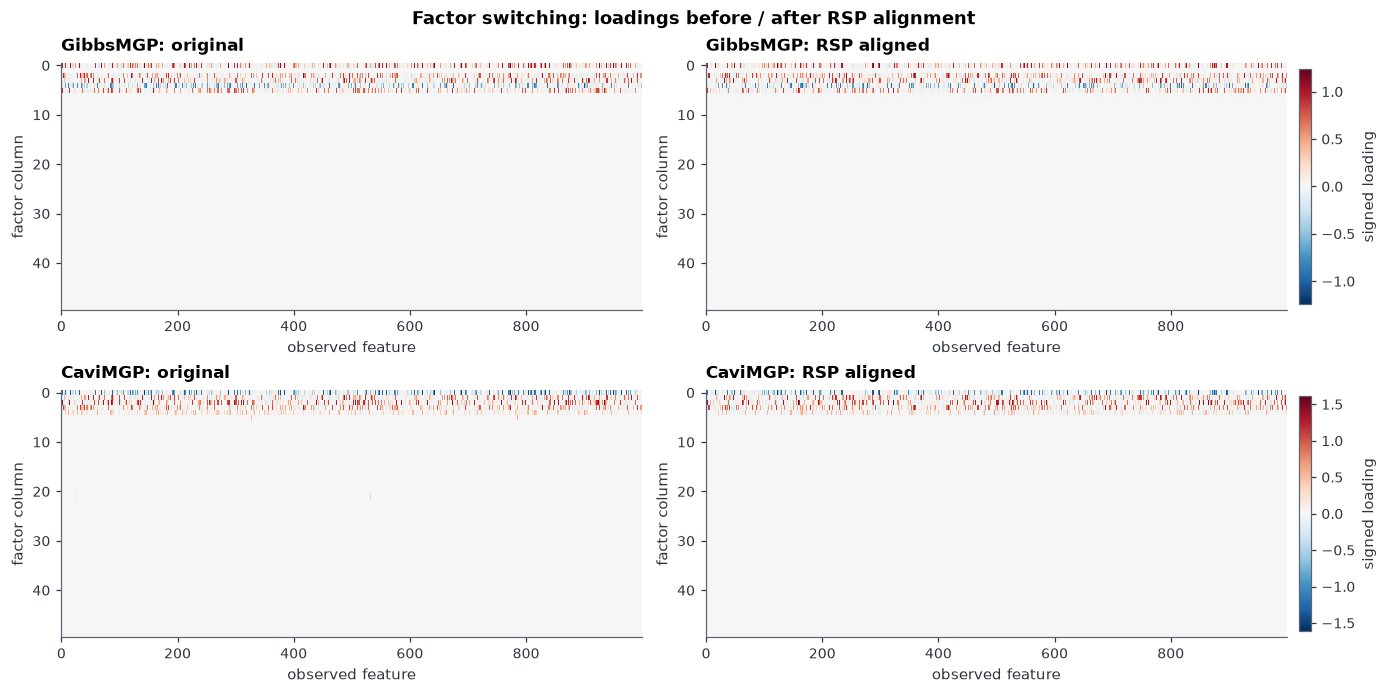

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.2), constrained_layout=True)
comparisons = (
    ("GibbsMGP", gs_mean_raw, gs.B_hat_),
    ("CaviMGP", vi_mean_raw, vi.mu_aligned_),
)
for row, (name, before, after) in enumerate(comparisons):
    limit = max(float(np.max(np.abs(before))), float(np.max(np.abs(after))), 1e-8)
    for col, (label, loadings) in enumerate((("original", before),
                                            ("RSP aligned", after))):
        ax = axes[row, col]
        im = ax.imshow(loadings.T, aspect="auto", interpolation="nearest",
                       cmap="RdBu_r", vmin=-limit, vmax=limit)
        ax.set_title(f"{name}: {label}", loc="left")
        ax.set_xlabel("observed feature")
        ax.set_ylabel("factor column")
        ax.grid(False)
    cb = fig.colorbar(im, ax=axes[row, :].tolist(), pad=0.01, shrink=0.95)
    cb.set_label("signed loading")
fig.suptitle("Factor switching: loadings before / after RSP alignment",
             fontweight="bold")
plt.show()

In [18]:
scores = gs.sample_factors(
    X, return_eta=True, return_eta_aligned=True, seed=SAMPLER_SEED, batch_size=32,
)
eta_sample = scores["eta_sample"]
eta_sample_aligned = scores["eta_sample_aligned"]
print("Gibbs eta_sample / eta_sample_aligned:",
      eta_sample.shape, eta_sample_aligned.shape, "(S, K, n)")
print("CAVI eta_aligned_ (posterior means):", vi.eta_aligned_.shape)
print("CAVI V_aligned_ / Phi_aligned_:", vi.V_aligned_.shape, vi.Phi_aligned_.shape)


def relative_difference(actual, expected):
    scale = max(float(np.linalg.norm(expected)), np.finfo(float).tiny)
    return float(np.linalg.norm(actual - expected)) / scale


s = gs.B_samples_.shape[0] // 2
B_raw_selected = gs.B_samples_[s, check_features]
B_aligned_selected = gs.B_aligned_[s, check_features]
common_raw = B_raw_selected @ eta_sample[s]
common_aligned = B_aligned_selected @ eta_sample_aligned[s]
np.testing.assert_allclose(common_aligned, common_raw, rtol=1e-4, atol=1e-4)
cov_raw = B_raw_selected @ B_raw_selected.T
cov_aligned = B_aligned_selected @ B_aligned_selected.T
np.testing.assert_allclose(cov_aligned, cov_raw, rtol=1e-4, atol=1e-4)
print(f"Gibbs draw {s}: relative B eta difference = "
      f"{relative_difference(common_aligned, common_raw):.3e}; "
      f"relative BB.T submatrix difference = "
      f"{relative_difference(cov_aligned, cov_raw):.3e}")

vi_common_raw = vi.mu_ @ vi.W_.T
vi_common_aligned = vi.mu_aligned_ @ vi.eta_aligned_
np.testing.assert_allclose(vi_common_aligned, vi_common_raw, rtol=1e-4, atol=1e-4)
vi_cov_raw = vi_mean_raw[check_features] @ vi_mean_raw[check_features].T
vi_cov_aligned = vi.mu_aligned_[check_features] @ vi.mu_aligned_[check_features].T
np.testing.assert_allclose(vi_cov_aligned, vi_cov_raw, rtol=1e-4, atol=1e-4)
print("CAVI relative common-component difference:",
      f"{relative_difference(vi_common_aligned, vi_common_raw):.3e}; "
      f"relative BB.T submatrix difference = "
      f"{relative_difference(vi_cov_aligned, vi_cov_raw):.3e}")

for name, model, raw_block in (
    ("Gibbs", gs, gs_sigma_mean_raw_block),
    ("CAVI", vi, vi_sigma_mean_raw_block),
):
    aligned_block = model.Sigma_mean_[check_pairs]
    np.testing.assert_allclose(aligned_block, raw_block, rtol=1e-12, atol=1e-12)
    print(f"{name} posterior-mean covariance is unchanged on selected features.")

gs_plugin_aligned_block = (gs.B_hat_[check_features]
                           @ gs.B_hat_[check_features].T + noise_block)
print("Gibbs plug-in Sigma_ relative change on selected features:",
      f"{relative_difference(gs_plugin_aligned_block, gs_plugin_raw_block):.3e}")
# Each draw preserves BB.T, but the plug-in outer product of the aligned mean can change.

Gibbs eta_sample / eta_sample_aligned: (1000, 50, 100) (1000, 50, 100) (S, K, n)
CAVI eta_aligned_ (posterior means): (50, 100)
CAVI V_aligned_ / Phi_aligned_: (1000, 50, 50) (50, 50)
Gibbs draw 500: relative B eta difference = 5.133e-07; relative BB.T submatrix difference = 4.547e-07
CAVI relative common-component difference: 1.339e-15; relative BB.T submatrix difference = 1.397e-15
Gibbs posterior-mean covariance is unchanged on selected features.
CAVI posterior-mean covariance is unchanged on selected features.
Gibbs plug-in Sigma_ relative change on selected features: 2.287e-03


## Summary

- Compare the current Gibbs credible-interval count and both CAVI counts (`credible` and `linf`, with `threshold=0.1`) against the true dimension $r=5$. Section 8a reports each count before and after independent alignment, followed by all 50 columns' posterior-mean $L_\infty$ norms.
- Use the current noise-recovery correlations and errors, absolute and relative covariance errors, top-$r$-by-norm subspace cosines, and ELBO trajectory to assess recovery. Read CAVI convergence status, stop reason, iteration count, and timings from the fit output rather than from historical benchmarks.
- Assess Gibbs mixing with the reported ESS summary, heatmap, histogram, and rolling noise trace. Inspect the RSP status and full diagnostics for both estimators.
- Inspect the loading plots and complete infinity-norm table to assess shrinkage and orientation. The assertions verify preservation of fitted common components, per-draw and posterior-mean covariance quantities, and CAVI's original-coordinate outputs; the Gibbs plug-in covariance is allowed to change after alignment.